**Писаренко Анастасия, отчет ML1**


Задача **многоклассовой классификации**.

Цель - предсказать оценку автомобиля (`evaluation_class`: unacceptable, acceptable, good, very_good) по его характеристикам (цена, пробег, мощность и т.д.).

Для этого обучаем и сравниваем три алгоритма машинного обучения:
- **KNN (K-ближайших соседей)** - простой алгоритм на основе поиска похожих объектов.
- **SVM (Машина опорных векторов)** - алгоритм, ищущий оптимальную границу между классами.
- **Random Forest (Случайный лес)** - ансамбль решающих деревьев, который голосованием выдает ответ.

In [1]:
!pip install kagglehub

In [2]:
from google.colab import files

uploaded = files.upload()
if not uploaded:
    raise RuntimeError("Загрузите файл kaggle.json")

uploaded_filename = next(iter(uploaded))
print(f"Загружен файл: {uploaded_filename}")


Saving kaggle.json to kaggle.json
Загружен файл: kaggle.json


In [3]:
from pathlib import Path
import shutil

kaggle_dir = Path.home() / ".kaggle"
kaggle_dir.mkdir(parents=True, exist_ok=True)

kaggle_credentials = kaggle_dir / "kaggle.json"
shutil.copyfile(uploaded_filename, kaggle_credentials)
kaggle_credentials.chmod(0o600)
print(f"Kaggle API настроен: {kaggle_credentials}")


Kaggle API настроен: /root/.kaggle/kaggle.json


In [4]:
import kagglehub
path = kagglehub.dataset_download("chaitanyajamble/car-evaluation")
print("Path to dataset files:", path)

Using Colab cache for faster access to the 'car-evaluation' dataset.
Path to dataset files: /kaggle/input/car-evaluation


# Импорт библиотек

- `pandas`, `numpy` - работа с таблицами и массивами;
- `matplotlib`, `seaborn` - визуализация;
- `glob` - поиск CSV-файлов на диске;
- `sklearn` - модели (KNN, SVM, RandomForest), препроцессинг (StandardScaler, OneHotEncoder),
  подбор гиперпараметров (GridSearchCV), метрики (classification_report, confusion_matrix, roc_auc_score), PCA;
- `scipy.cdist` - матрица попарных расстояний для собственного SMOTE.

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import glob
from sklearn.base import BaseEstimator, ClassifierMixin, clone
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler, LabelEncoder, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, ConfusionMatrixDisplay
from sklearn.decomposition import PCA
from sklearn.preprocessing import label_binarize
from scipy.spatial.distance import cdist
import warnings
warnings.filterwarnings('ignore')


In [6]:
csv_files = glob.glob(path + "/*.csv")
df = pd.read_csv(csv_files[0])

# Первичная очистка столбцов

- Удаляем `car_id` (идентификатор, не несёт смысла),
  `customer_review_text` (текст, не обрабатываем NLP),
  `model` (слишком много уникальных значений - риск переобучения).
- `inspection_date` конвертируем в `datetime`, извлекаем год в отдельный признак `inspection_year`,
  а исходный столбец удаляем - год удобнее и числовой.

In [7]:
df = df.drop(columns=['car_id', 'customer_review_text', 'model'])
df['inspection_date'] = pd.to_datetime(df['inspection_date'], errors='coerce')
df['inspection_year'] = df['inspection_date'].dt.year
df = df.drop(columns=['inspection_date'])

# Проверка пропусков до обработки

Показываем количество пропусков по каждому признаку и суммарно.
Видим 898 пропусков: 150 в `annual_maintenance_usd`, 250 в `horsepower`,
398 в `mileage_km`, 100 в `owner_count`.

In [8]:
print("Пропуски до обработки:")
print(df.isnull().sum())
print(f"Всего пропусков до обработки: {df.isnull().sum().sum()}")

Пропуски до обработки:
brand                       0
manufacture_year            0
region                      0
buying_price_level          0
price_usd                   0
maintenance_cost_level      0
annual_maintenance_usd    150
doors                       0
seating_capacity            0
luggage_boot_size           0
safety_rating               0
fuel_type                   0
transmission                0
engine_size_l               0
horsepower                250
mileage_km                398
owner_count               100
evaluation_class            0
inspection_year             0
dtype: int64
Всего пропусков до обработки: 898


# Анализ целевой переменной

Смотрим распределение классов `evaluation_class`:
- `unacceptable` - 70 %;
- `acceptable` - 22 %;
- `good` - 4.5 %;
- `very_good` - 3.5 %.

Явный дисбаланс - нужно учитывать при обучении и оценке.

Это критически важно, потому что при сильном дисбалансе **accuracy** (доля правильных ответов) становится обманчивой. Модель, которая всегда предсказывает «unacceptable», может показать высокую accuracy, но ничего не найдет из редких классов.

In [9]:
target_col = 'evaluation_class'
print(f"Целевая переменная: {target_col}")
print(df[target_col].value_counts())
print(df[target_col].value_counts(normalize=True))

Целевая переменная: evaluation_class
evaluation_class
unacceptable    7000
acceptable      2200
good             450
very_good        350
Name: count, dtype: int64
evaluation_class
unacceptable    0.700
acceptable      0.220
good            0.045
very_good       0.035
Name: proportion, dtype: float64


Явный дисбаланс 70 / 22 / 4.5 / 3.5 %.

Поэтому для оценки качества мы не можем полагаться только на Accuracy. Для оптимизации в GridSearchCV будем использовать `f1_weighted` (учитывает размер классов), а смотреть ещё macro F1 (штрафует за плохие редкие классы), ROC-AUC и confusion matrix.

**Precision** - из всех объектов, которые модель назвала классом X, сколько реально оказались классом X. (Насколько можно доверять модели, когда она говорит "это X").

**Recall** - из всех реально существующих объектов класса X, сколько модель смогла найти. (Насколько полно модель находит этот класс).

F1 - их среднее гармоническое. Подробнее разберем на этапе оценки

# Разделение признаков по типам

- `num_cols` - числовые признаки (для StandardScaler);
- `cat_cols` - категориальные (для OneHotEncoder).

Целевую переменную исключаем из обоих списков.

In [10]:
num_cols = df.select_dtypes(include=[np.number]).columns.tolist()
cat_cols = df.select_dtypes(include=['object']).columns.tolist()
if target_col in cat_cols:
    cat_cols.remove(target_col)
if target_col in num_cols:
    num_cols.remove(target_col)

# Гистограммы числовых признаков

Строим распределение каждого числового признака (`sns.histplot` + KDE).
Видим скошенные распределения (`price_usd`, `mileage_km`, `horsepower`) -
это обосновывает масштабирование и устойчивые к выбросам модели.

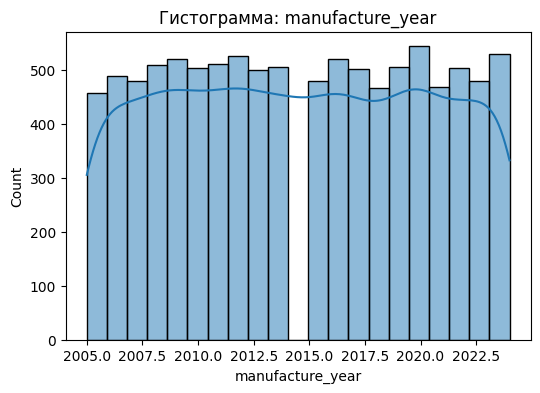

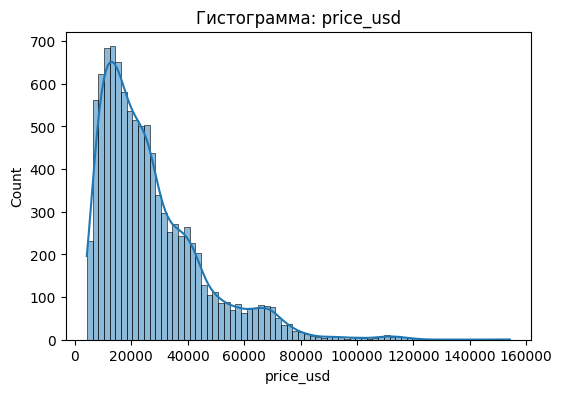

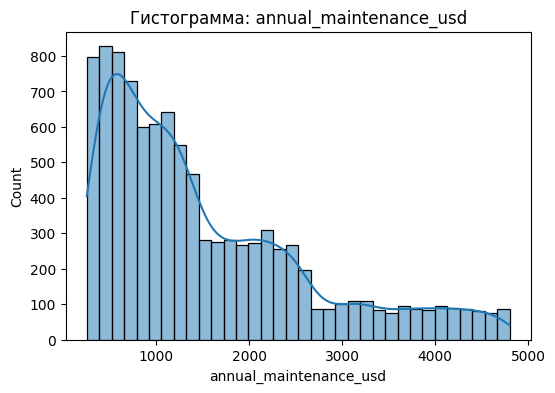

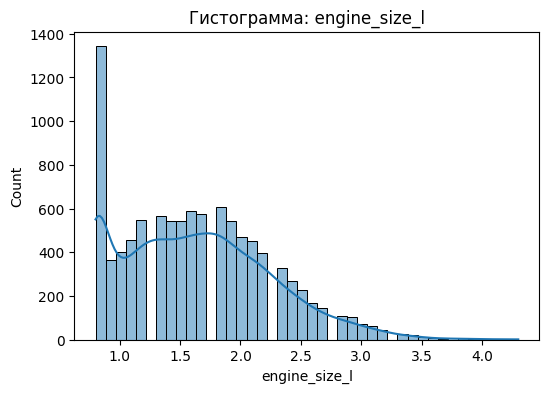

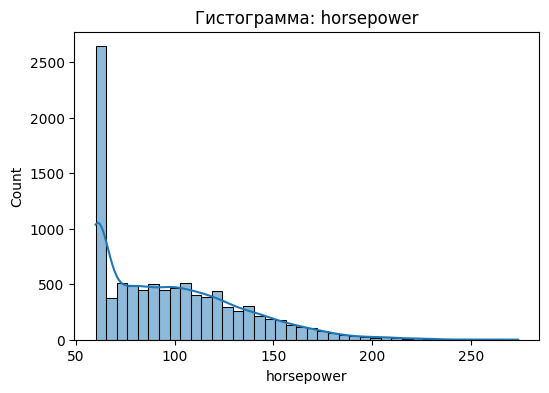

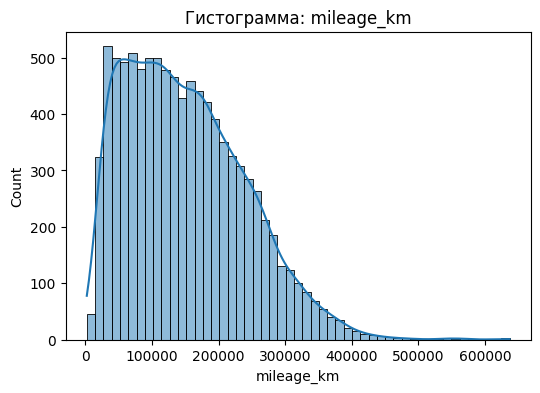

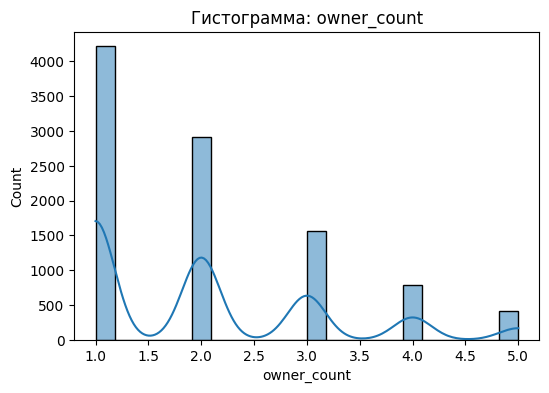

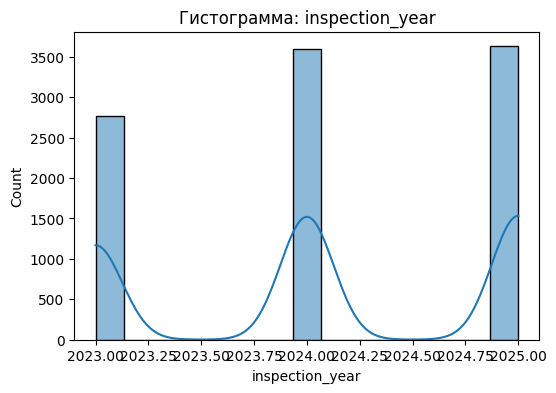

In [11]:
for col in num_cols:
    plt.figure(figsize=(6,4))
    sns.histplot(df[col].dropna(), kde=True)
    plt.title(f'Гистограмма: {col}')
    plt.show()

# Ящики с усами по классам

Для каждого числового признака строим `boxplot` в разрезе классов.
Хорошо видны выбросы (например, по `price_usd`, `mileage_km`, `horsepower`).
Их не удаляем - это реальные объекты, а модели (RF) устойчивы к выбросам.

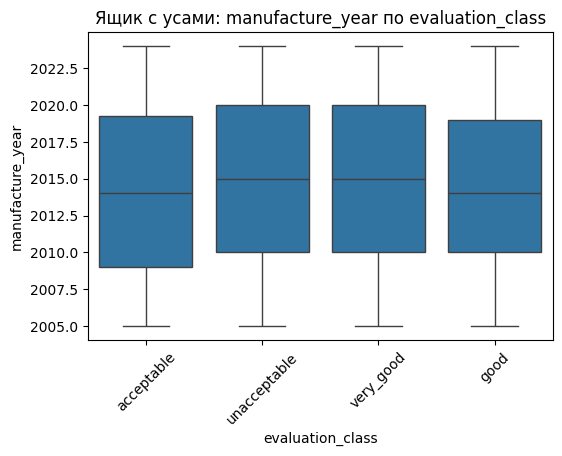

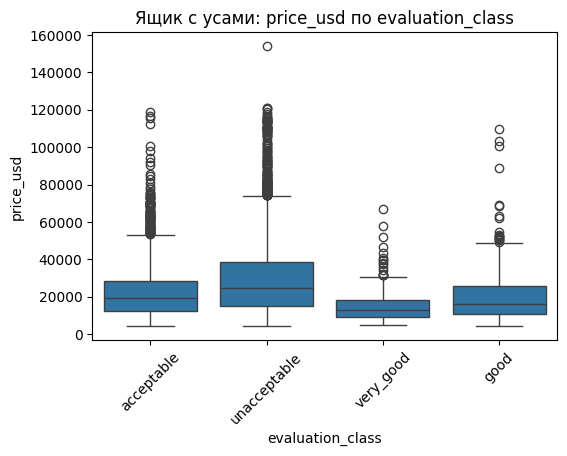

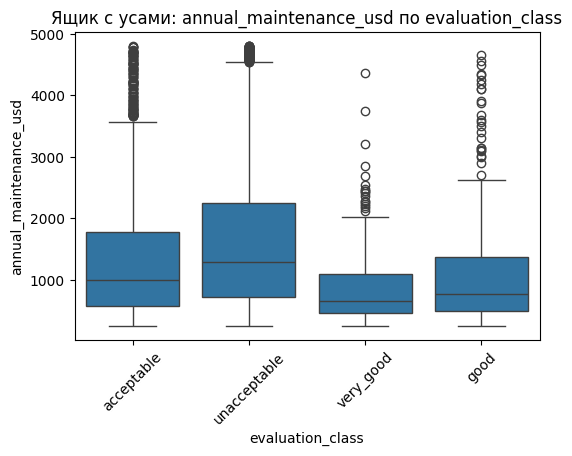

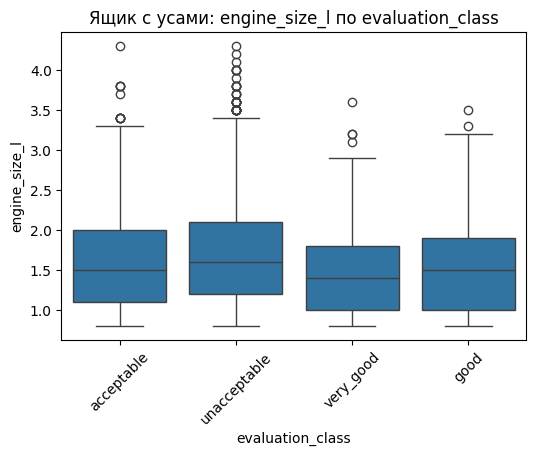

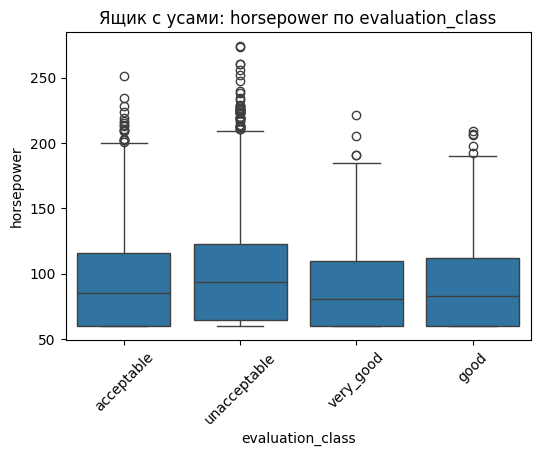

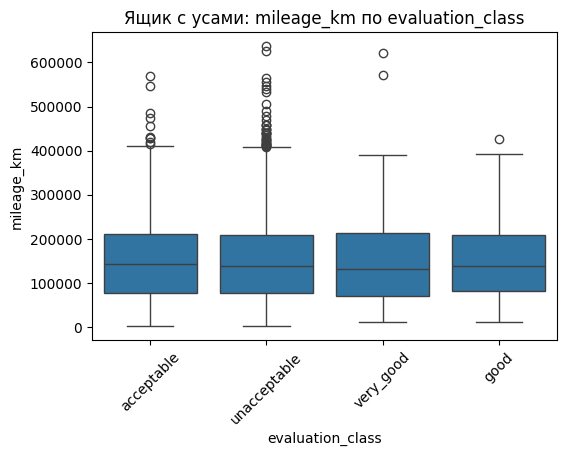

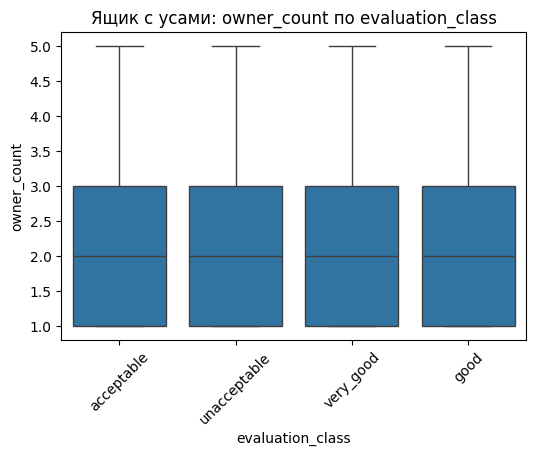

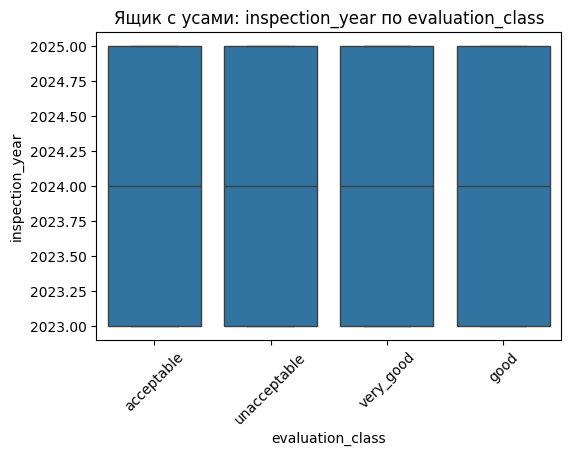

In [12]:
for col in num_cols:
    plt.figure(figsize=(6,4))
    sns.boxplot(x=df[target_col], y=df[col])
    plt.title(f'Ящик с усами: {col} по {target_col}')
    plt.xticks(rotation=45)
    plt.show()

# Матрица корреляций

Тепловая карта корреляций числовых признаков.
Ключевые наблюдения:
- `manufacture_year` ↔ `mileage_km` ≈ −0.84 (сильная обратная);
- `engine_size_l` ↔ `horsepower` ≈ 0.82 (сильная прямая);
- `price_usd` ↔ `engine_size_l` ≈ 0.46, `price_usd` ↔ `horsepower` ≈ 0.39.

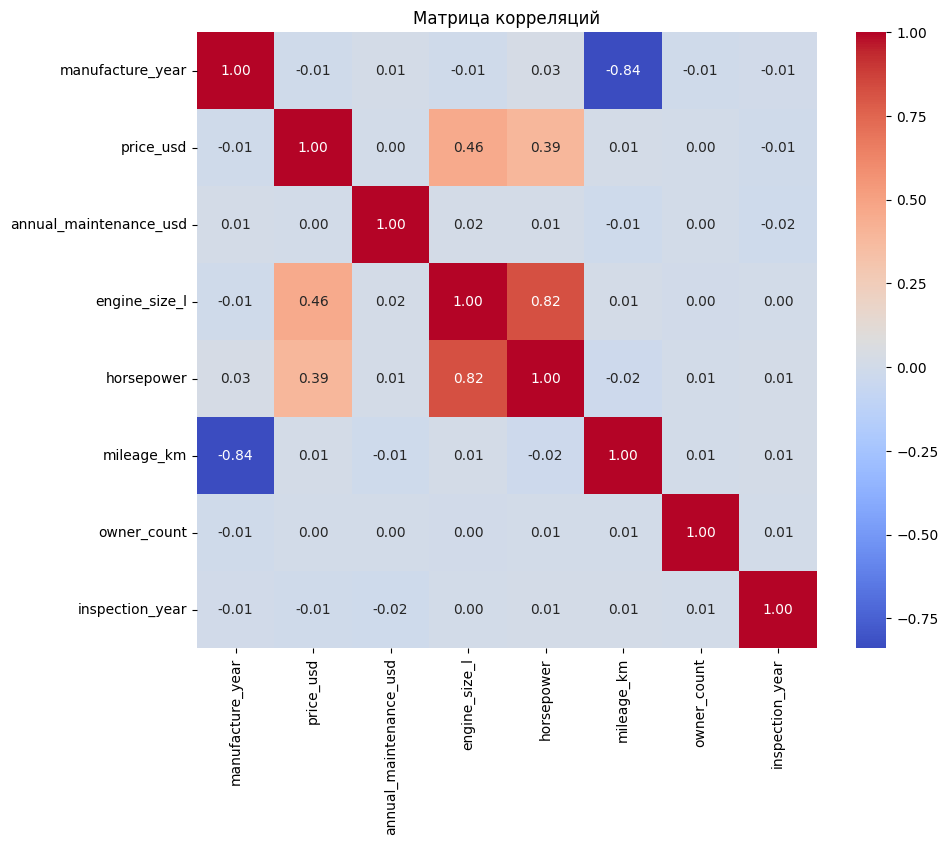

In [13]:
plt.figure(figsize=(10,8))
corr = df[num_cols].corr()
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Матрица корреляций')
plt.show()

# Pairplot (диаграммы рассеяния)

Матрица диаграмм рассеяния с раскраской по классам.
Видно, что классы сильно перемешаны - линейного разделения нет,
значит нужны нелинейные модели (SVM с RBF, Random Forest).

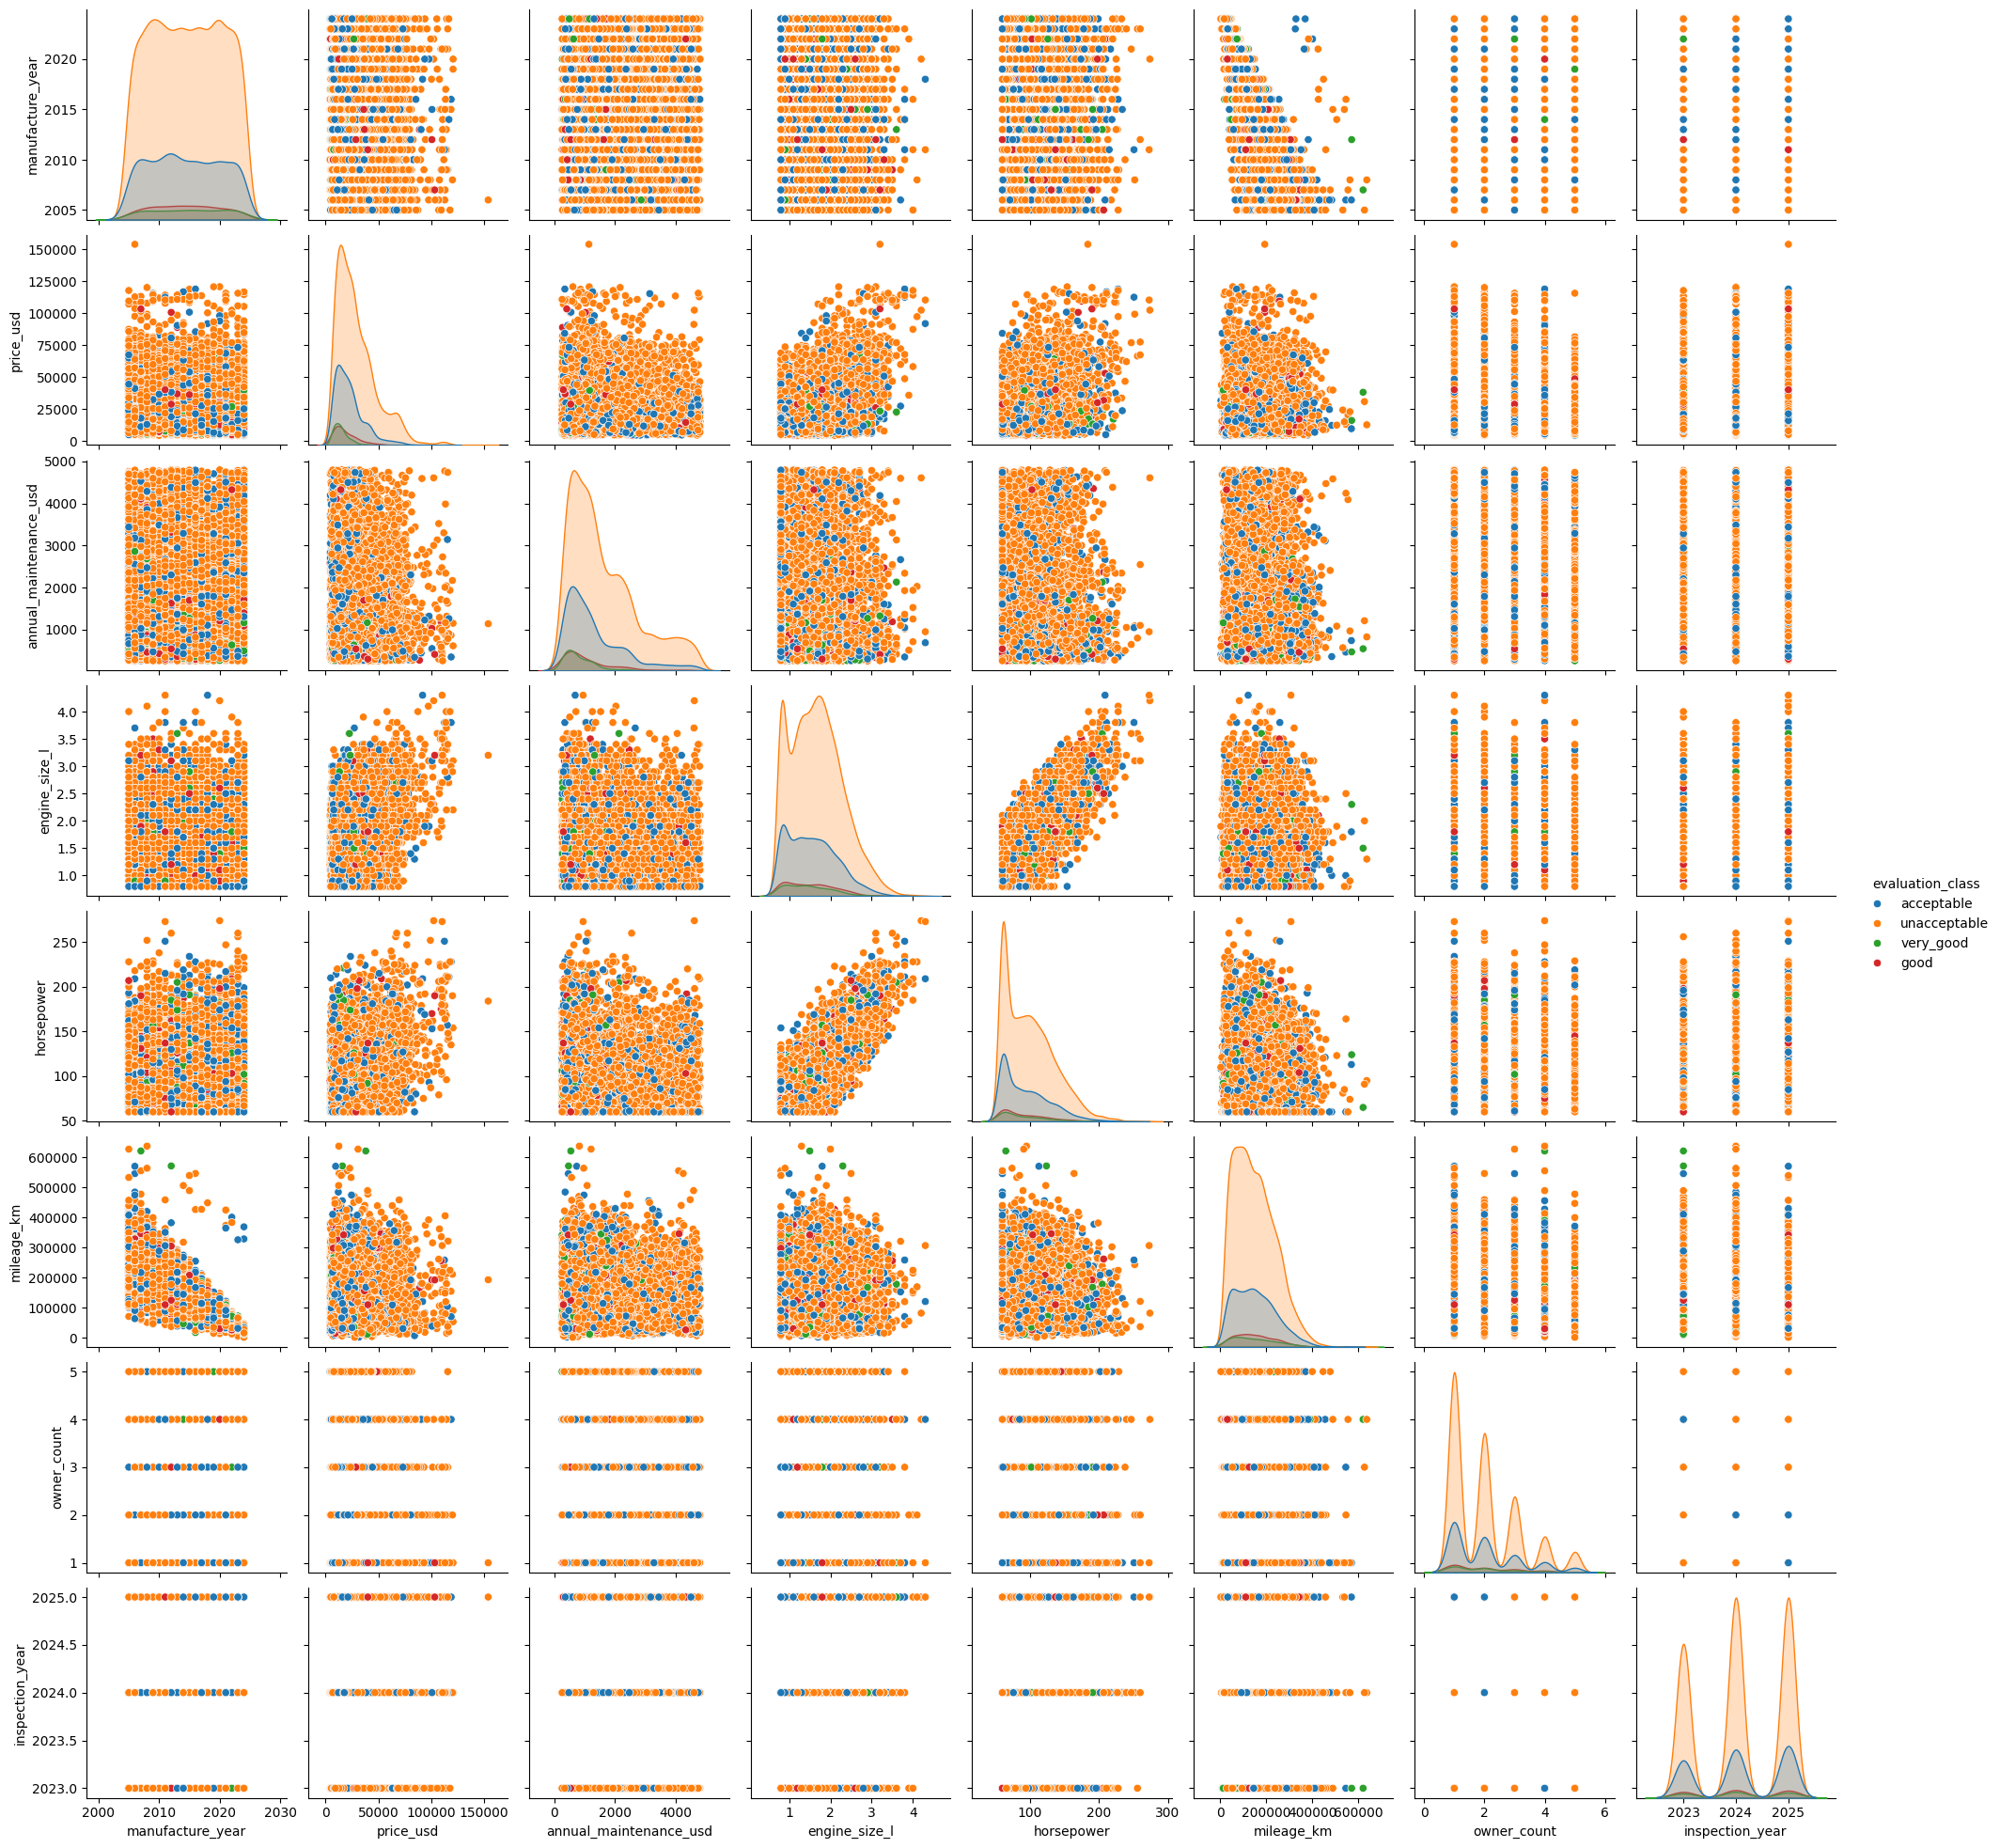

In [14]:
sns.pairplot(df[num_cols + [target_col]], hue=target_col)
plt.show()

# Удаление дубликатов и стратегия обработки пропусков

- Удаляем точные дубликаты (`drop_duplicates`).
- **Не вычисляем медианы и моды на всём датасете.** Иначе объекты из test влияли бы на обучающий препроцессинг.
- Числовые пропуски заполняются медианой, категориальные - модой через `SimpleImputer`.
- Imputer обучается отдельно на каждом обучающем фолде внутри `GridSearchCV`, а к validation/test применяется только через `transform`.


In [15]:
df = df.drop_duplicates().reset_index(drop=True)


# Контроль пропусков перед pipeline

Ниже показаны исходные пропуски после удаления дубликатов. Они намеренно остаются в данных до обучения:
заполнение выполняется без утечки внутри каждого CV-фолда.


In [16]:
print("Пропуски перед обучением pipeline:")
print(df.isnull().sum())
print(f"Всего пропусков: {df.isnull().sum().sum()}")


Пропуски перед обучением pipeline:
brand                       0
manufacture_year            0
region                      0
buying_price_level          0
price_usd                   0
maintenance_cost_level      0
annual_maintenance_usd    150
doors                       0
seating_capacity            0
luggage_boot_size           0
safety_rating               0
fuel_type                   0
transmission                0
engine_size_l               0
horsepower                250
mileage_km                398
owner_count               100
evaluation_class            0
inspection_year             0
dtype: int64
Всего пропусков: 898


# Подготовка X, y и разбиение

- `X` - признаки, `y` - целевая переменная.
- `LabelEncoder` переводит классы в числа 0..3.
- `train_test_split` с `stratify=y_encoded` сохраняет пропорции классов
  в train и test (важно при дисбалансе).

In [17]:
X = df.drop(columns=[target_col])
y = df[target_col]

le = LabelEncoder()
y_encoded = le.fit_transform(y)
num_classes = len(le.classes_)
print(f"Классы: {le.classes_}")

X_train, X_test, y_train, y_test = train_test_split(
    X, y_encoded, test_size=0.2, random_state=42, stratify=y_encoded
)

Классы: ['acceptable' 'good' 'unacceptable' 'very_good']


# Состав признаков после очистки

Итог: 18 признаков - 8 числовых и 10 категориальных.

In [18]:
print(f"Количество признаков после очистки: {X.shape[1]}")
print(f"Числовых признаков: {len(num_cols)}")
print(f"Категориальных признаков: {len(cat_cols)}")
print("Числовые признаки:", num_cols)
print("Категориальные признаки:", cat_cols)

Количество признаков после очистки: 18
Числовых признаков: 8
Категориальных признаков: 10
Числовые признаки: ['manufacture_year', 'price_usd', 'annual_maintenance_usd', 'engine_size_l', 'horsepower', 'mileage_km', 'owner_count', 'inspection_year']
Категориальные признаки: ['brand', 'region', 'buying_price_level', 'maintenance_cost_level', 'doors', 'seating_capacity', 'luggage_boot_size', 'safety_rating', 'fuel_type', 'transmission']


# Собственный SMOTE

Реализация SMOTE без готового алгоритма балансировки из `imblearn`.

Алгоритм:
- Для каждого миноритарного класса находим ближайших соседей по стандартизованным числовым признакам.
- Числовые признаки синтетического объекта получаем линейной интерполяцией между объектом и его соседом.
- Категориальные признаки наследуем случайно от одного из двух родителей.
- Повторяем, пока класс не сравняется с мажоритарным.

Исправления граничных случаев:
- индексы `X` и `y` синхронно сбрасываются;
- используется `k_eff = min(k, count - 1)`, поэтому сам объект не попадает в список соседей;
- класс из одного объекта пропускается с предупреждением, а не дублируется неявно;
- локальный генератор случайных чисел не меняет глобальный random state NumPy.

**Балансировка выполняется только на обучающей части каждого CV-фолда.**


In [19]:
def custom_smote(X, y, k=5, random_state=42):
    """Балансирует смешанные данные, не используя объекты вне переданного набора."""
    if not isinstance(k, (int, np.integer)) or k < 1:
        raise ValueError("k должен быть положительным целым числом")

    X = X.reset_index(drop=True).copy()
    y = pd.Series(y).reset_index(drop=True)

    if len(X) != len(y):
        raise ValueError("X и y должны содержать одинаковое число объектов")
    if X.empty:
        raise ValueError("Нельзя выполнить SMOTE на пустом наборе")

    rng = np.random.default_rng(random_state)
    classes, counts = np.unique(y, return_counts=True)
    max_count = counts.max()

    X_resampled = X.copy()
    y_resampled = y.copy()

    for cls, count in zip(classes, counts):
        if count == max_count:
            continue

        if count < 2:
            warnings.warn(
                f"Класс {cls!r} содержит меньше двух объектов и не может быть "
                "обработан SMOTE; класс оставлен без синтетических объектов."
            )
            continue

        n_needed = max_count - count
        X_cls = X.loc[y.to_numpy() == cls].reset_index(drop=True)

        num_cols_local = X_cls.select_dtypes(include=[np.number]).columns.tolist()
        cat_cols_local = X_cls.select_dtypes(include=['object']).columns.tolist()

        if len(num_cols_local) > 0:
            scaler = StandardScaler()
            X_num_scaled = scaler.fit_transform(X_cls[num_cols_local])
        else:
            # Если числовых признаков нет, соседи выбираются случайно.
            X_num_scaled = np.zeros((len(X_cls), 1))

        dist_matrix = cdist(X_num_scaled, X_num_scaled, metric='euclidean')
        np.fill_diagonal(dist_matrix, np.inf)

        # Доступно не более count - 1 настоящих соседей: сам объект исключён.
        k_eff = min(k, count - 1)
        neighbors = np.argsort(dist_matrix, axis=1)[:, :k_eff]

        synthetic_num = []
        synthetic_cat = []

        for _ in range(n_needed):
            idx = rng.integers(0, len(X_cls))
            neigh_idx = rng.choice(neighbors[idx])

            if len(num_cols_local) > 0:
                base_num = X_cls.iloc[idx][num_cols_local].to_numpy(dtype=float)
                neighbor_num = X_cls.iloc[neigh_idx][num_cols_local].to_numpy(dtype=float)
                weight = rng.random()
                synthetic_num.append(base_num + weight * (neighbor_num - base_num))

            if len(cat_cols_local) > 0:
                new_cat = []
                for col in cat_cols_local:
                    val = rng.choice([X_cls.iloc[idx][col], X_cls.iloc[neigh_idx][col]])
                    new_cat.append(val)
                synthetic_cat.append(new_cat)

        if len(num_cols_local) > 0:
            synth_df_num = pd.DataFrame(
                np.asarray(synthetic_num), columns=num_cols_local
            )
        else:
            synth_df_num = pd.DataFrame(index=range(n_needed))

        if len(cat_cols_local) > 0:
            synth_df_cat = pd.DataFrame(synthetic_cat, columns=cat_cols_local)
        else:
            synth_df_cat = pd.DataFrame(index=range(n_needed))

        synth_df = pd.concat([synth_df_num, synth_df_cat], axis=1)

        for col in X.columns:
            if col not in synth_df.columns:
                synth_df[col] = X_cls.iloc[0][col]
        synth_df = synth_df[X.columns]

        X_resampled = pd.concat([X_resampled, synth_df], ignore_index=True)
        y_resampled = pd.concat(
            [y_resampled, pd.Series([cls] * n_needed)], ignore_index=True
        )

    return X_resampled, y_resampled


# Балансировка только внутри обучающих фолдов

Здесь **не создаём** общие `X_train_bal` и `y_train_bal` до кросс-валидации.
Иначе validation-фолд мог бы получить синтетические объекты, построенные по объектам из train-фолда.

`ResamplingClassifier` ниже вызывает SMOTE только внутри `fit`. Поэтому для каждого фолда порядок такой:
`imputer.fit` → `SMOTE` → `preprocessor.fit` → `classifier.fit`.


In [20]:
print("Распределение классов в исходном train:", np.bincount(y_train))
print("SMOTE будет применён независимо внутри каждого обучающего CV-фолда.")


Распределение классов в исходном train: [1760  360 5600  280]
SMOTE будет применён независимо внутри каждого обучающего CV-фолда.


# Препроцессинг и балансировка внутри GridSearchCV

`ResamplingClassifier` объединяет четыре операции:

- `SimpleImputer` - медиана для числовых и мода для категориальных признаков;
- собственный SMOTE - только для обучающей части;
- `StandardScaler` и `OneHotEncoder(handle_unknown='ignore')`;
- классификатор KNN, SVM или Random Forest.

При кросс-валидации `GridSearchCV` вызывает `fit` отдельно на каждом train-фолде.
Validation/test участвуют только в `transform` и `predict`, поэтому утечки через imputation, SMOTE и препроцессинг устранены.


In [21]:
numeric_features = X.select_dtypes(include=[np.number]).columns.tolist()
categorical_features = X.select_dtypes(include=['object']).columns.tolist()


def make_imputer():
    imputer = ColumnTransformer(
        transformers=[
            ('num', SimpleImputer(strategy='median'), numeric_features),
            ('cat', SimpleImputer(strategy='most_frequent'), categorical_features)
        ],
        verbose_feature_names_out=False
    )
    # custom_smote нужен DataFrame с исходными именами и типами столбцов.
    imputer.set_output(transform='pandas')
    return imputer


def make_preprocessor():
    return ColumnTransformer(
        transformers=[
            ('num', StandardScaler(), numeric_features),
            ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features)
        ]
    )


class ResamplingClassifier(ClassifierMixin, BaseEstimator):
    """Estimator, весь препроцессинг и SMOTE которого выполняется внутри fit."""

    def __init__(self, classifier, numeric_features, categorical_features,
                 k=5, random_state=42):
        self.classifier = classifier
        self.numeric_features = numeric_features
        self.categorical_features = categorical_features
        self.k = k
        self.random_state = random_state

    def fit(self, X, y):
        X = X.copy()
        y = pd.Series(y).reset_index(drop=True)

        self.imputer_ = make_imputer()
        X_imputed = self.imputer_.fit_transform(X)

        X_resampled, y_resampled = custom_smote(
            X_imputed, y, k=self.k, random_state=self.random_state
        )

        self.preprocessor_ = make_preprocessor()
        X_processed = self.preprocessor_.fit_transform(X_resampled)

        self.classifier_ = clone(self.classifier)
        self.classifier_.fit(X_processed, y_resampled)

        self.classes_ = self.classifier_.classes_
        self.n_features_in_ = X.shape[1]
        if hasattr(X, 'columns'):
            self.feature_names_in_ = np.asarray(X.columns, dtype=object)
        return self

    def _transform(self, X):
        X_imputed = self.imputer_.transform(X)
        return self.preprocessor_.transform(X_imputed)

    def predict(self, X):
        return self.classifier_.predict(self._transform(X))

    def predict_proba(self, X):
        if not hasattr(self.classifier_, 'predict_proba'):
            raise AttributeError(
                f"{type(self.classifier_).__name__} не поддерживает predict_proba"
            )
        return self.classifier_.predict_proba(self._transform(X))

    def decision_function(self, X):
        if not hasattr(self.classifier_, 'decision_function'):
            raise AttributeError(
                f"{type(self.classifier_).__name__} не поддерживает decision_function"
            )
        return self.classifier_.decision_function(self._transform(X))


# KNN + GridSearchCV

Перебираем:
- `n_neighbors`: [3, 5, 7, 9, 11];
- `weights`: ['uniform', 'distance'];
- `metric`: ['euclidean', 'manhattan'].

5-кратная кросс-валидация, метрика `f1_weighted`.
Префикс `classifier__` означает, что параметр относится к KNN внутри `ResamplingClassifier`.
После выбора параметров лучший estimator заново обучается на всём train, включая безопасные imputation, SMOTE и preprocessing.

KNN остаётся чувствительным к размерности, масштабу и шуму. Качество редких классов оцениваем по фактическому classification report, а не предполагаем заранее.


In [22]:
knn = ResamplingClassifier(
    KNeighborsClassifier(algorithm='kd_tree'),
    numeric_features,
    categorical_features
)

knn_params = {
    'classifier__n_neighbors': [3, 5, 7],
    'classifier__weights': ['uniform', 'distance'],
    'classifier__metric': ['euclidean']
}

knn_grid = GridSearchCV(knn, knn_params, cv=3, scoring='f1_weighted', n_jobs=-1)
knn_grid.fit(X_train, y_train)

best_knn = knn_grid.best_estimator_
print("KNN лучшие параметры:", knn_grid.best_params_)

KNN лучшие параметры: {'classifier__metric': 'euclidean', 'classifier__n_neighbors': 7, 'classifier__weights': 'distance'}


# SVM + GridSearchCV

Перебираем:
- `C`: [1, 10];
- `kernel`: ['rbf'];
- `gamma`: ['scale'].

Для SVM используется 3-кратная кросс-валидация как компромисс по времени вычислений.
Все обучающие преобразования и SMOTE выполняются независимо внутри каждого фолда.

RBF-ядро позволяет строить нелинейную разделяющую границу в исходном пространстве признаков.


In [23]:
svm = ResamplingClassifier(
    SVC(cache_size=1000),
    numeric_features,
    categorical_features
)

svm_params = {
    'classifier__C': [1, 10],
    'classifier__kernel': ['rbf'],
    'classifier__gamma': ['scale']
}

svm_grid = GridSearchCV(svm, svm_params, cv=3, scoring='f1_weighted', n_jobs=-1)
svm_grid.fit(X_train, y_train)

best_svm = svm_grid.best_estimator_
print("SVM лучшие параметры:", svm_grid.best_params_)

SVM лучшие параметры: {'classifier__C': 1, 'classifier__gamma': 'scale', 'classifier__kernel': 'rbf'}


# Random Forest + GridSearchCV

Перебираем:
- `n_estimators`: [100, 200];
- `max_depth`: [None, 10, 20];
- `min_samples_split`: [2, 5].

5-кратная кросс-валидация, `f1_weighted`.

Random Forest может хорошо моделировать нелинейности и взаимодействия признаков, относительно устойчив к выбросам и не требует масштабирования.
**Стандартный Random Forest не является устойчивым к дисбалансу сам по себе.** Здесь балансировку обеспечивает SMOTE внутри обучающих фолдов; альтернативами могли бы быть `class_weight='balanced'` или `'balanced_subsample'`.


In [24]:
rf = ResamplingClassifier(
    RandomForestClassifier(random_state=42, n_jobs=1),
    numeric_features,
    categorical_features
)

rf_params = {
    'classifier__n_estimators': [100],
    'classifier__max_depth': [None, 10],
}

rf_grid = GridSearchCV(rf, rf_params, cv=3, scoring='f1_weighted', n_jobs=-1)
rf_grid.fit(X_train, y_train)

best_rf = rf_grid.best_estimator_
print("RF лучшие параметры:", rf_grid.best_params_)

RF лучшие параметры: {'classifier__max_depth': None, 'classifier__n_estimators': 100}


### Macro F1 vs Weighted F1

- **macro F1** - простое среднее F1 по классам; каждый класс имеет одинаковый вес.
- **weighted F1** - среднее с весами `support`; на несбалансированном test крупные классы влияют сильнее.

Внутри GridSearchCV классы после SMOTE сбалансированы, поэтому `weighted F1` и `macro F1` там практически совпадают.
На исходном несбалансированном test основной метрикой для сравнения качества по всем классам считаем **macro F1**, а `weighted F1` оставляем как дополнительную сводную метрику. Отдельно анализируем precision, recall и F1 редких классов.


# Оценка моделей

Для каждой модели:
- выводим `classification_report` (precision, recall, F1, support, macro и weighted average);
- строим `confusion_matrix` с подписями классов.

Все модели получают исходный `X_test`: обученные внутри estimator imputer и preprocessor сами выполнят необходимые преобразования.
Численные результаты появятся после повторного выполнения ноутбука; старые результаты удалены, поскольку были получены другим pipeline.



--- KNN ---
              precision    recall  f1-score   support

  acceptable       0.37      0.47      0.42       440
        good       0.12      0.43      0.19        90
unacceptable       0.95      0.61      0.75      1400
   very_good       0.18      0.54      0.27        70

    accuracy                           0.57      2000
   macro avg       0.41      0.52      0.40      2000
weighted avg       0.76      0.57      0.63      2000



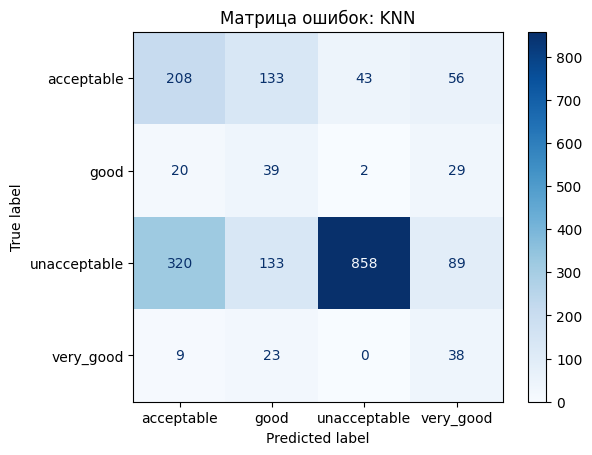


--- SVM ---
              precision    recall  f1-score   support

  acceptable       0.61      0.79      0.69       440
        good       0.33      0.43      0.38        90
unacceptable       0.98      0.87      0.92      1400
   very_good       0.58      0.57      0.58        70

    accuracy                           0.82      2000
   macro avg       0.63      0.67      0.64      2000
weighted avg       0.85      0.82      0.83      2000



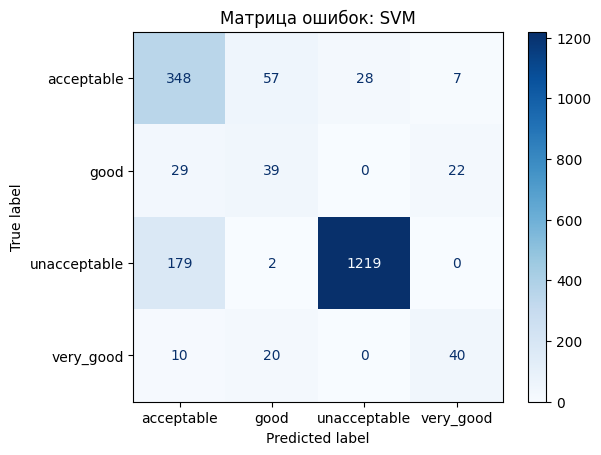


--- Random Forest ---
              precision    recall  f1-score   support

  acceptable       0.66      0.80      0.73       440
        good       0.34      0.47      0.39        90
unacceptable       0.98      0.90      0.94      1400
   very_good       0.57      0.53      0.55        70

    accuracy                           0.84      2000
   macro avg       0.64      0.67      0.65      2000
weighted avg       0.87      0.84      0.85      2000



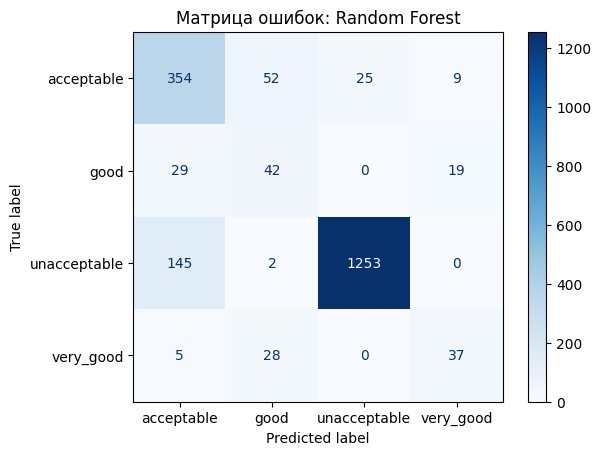

In [25]:
models = {'KNN': best_knn, 'SVM': best_svm, 'Random Forest': best_rf}
for name, model in models.items():
    y_pred = model.predict(X_test)
    print(f"\n--- {name} ---")
    print(classification_report(y_test, y_pred, target_names=le.classes_))
    cm = confusion_matrix(y_test, y_pred)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=le.classes_)
    disp.plot(cmap='Blues')
    plt.title(f'Матрица ошибок: {name}')
    plt.show()


# ROC-AUC для многоклассовой задачи

- Бинаризуем `y_test` через `label_binarize`.
- Для моделей с `predict_proba` используем вероятности.
- Для SVM без калибровки используем `decision_function` как **ранжирующую оценку, а не вероятность**.
  ROC-AUC допускает такие scores: для неё важен порядок ранжирования, а не калибровка.
  Мы не предполагаем монотонную связь этих значений с истинными вероятностями и не используем их для log loss или Brier score.
- Усреднение: `multi_class='ovr'`, `average='weighted'`; дополнительно выводим `macro` ROC-AUC.

Численные результаты появятся после повторного выполнения ноутбука.


In [26]:
y_test_bin = label_binarize(y_test, classes=range(num_classes))
for name, model in models.items():
    if hasattr(model.classifier_, 'predict_proba'):
        y_score = model.predict_proba(X_test)
    elif hasattr(model.classifier_, 'decision_function'):
        y_score = model.decision_function(X_test)
    else:
        print(f"{name}: невозможно получить оценки для ROC-AUC")
        continue

    auc_weighted = roc_auc_score(
        y_test_bin, y_score, multi_class='ovr', average='weighted'
    )
    auc_macro = roc_auc_score(
        y_test_bin, y_score, multi_class='ovr', average='macro'
    )
    print(
        f"{name} ROC-AUC (OvR): "
        f"weighted={auc_weighted:.4f}, macro={auc_macro:.4f}"
    )


KNN ROC-AUC (OvR): weighted=0.8289, macro=0.7836
SVM ROC-AUC (OvR): weighted=0.9405, macro=0.9160
Random Forest ROC-AUC (OvR): weighted=0.9700, macro=0.9571


# Feature Importance (Random Forest)

Извлекаем обученные preprocessor и Random Forest из `best_rf`.
Важности относятся к признакам после OneHotEncoder и описывают только вклад в данную модель, а не причинно-следственную зависимость.


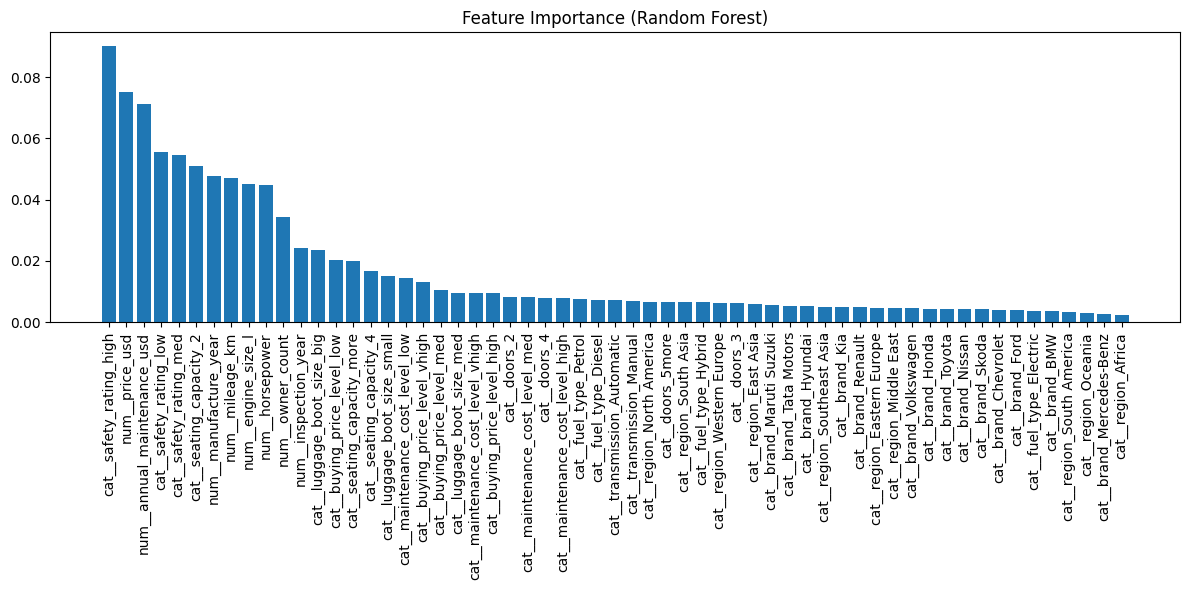

In [27]:
rf_model = best_rf.classifier_
fitted_preprocessor = best_rf.preprocessor_
feature_names = fitted_preprocessor.get_feature_names_out()

importances = rf_model.feature_importances_
indices = np.argsort(importances)[::-1]
plt.figure(figsize=(12, 6))
plt.title("Feature Importance (Random Forest)")
plt.bar(range(len(importances)), importances[indices])
plt.xticks(
    range(len(importances)),
    [feature_names[i] for i in indices],
    rotation=90
)
plt.tight_layout()
plt.show()


# PCA-визуализация

- Применяем обученные imputer и preprocessor из `best_rf` к `X_test`.
- `PCA(n_components=2)` используется только для визуализации, а не для обучения или оценки модели.
- Раскрашиваем точки по предсказаниям Random Forest.

Двумерная проекция не сохраняет всю структуру данных, поэтому по ней нельзя делать категоричный вывод о качестве классификатора.


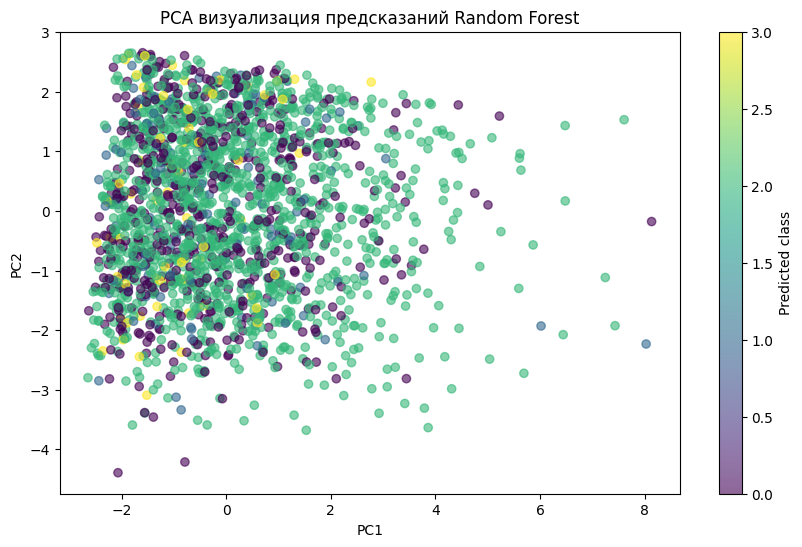

In [28]:
X_test_imputed = best_rf.imputer_.transform(X_test)
X_test_processed = best_rf.preprocessor_.transform(X_test_imputed)
y_pred_rf = best_rf.predict(X_test)

pca = PCA(n_components=2)
X_test_pca = pca.fit_transform(X_test_processed)

plt.figure(figsize=(10, 6))
scatter = plt.scatter(
    X_test_pca[:, 0], X_test_pca[:, 1],
    c=y_pred_rf, cmap='viridis', alpha=0.6
)
plt.colorbar(scatter, label='Predicted class')
plt.title('PCA визуализация предсказаний Random Forest')
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.show()


# Итоги

- Датасет: Car Evaluation, 4 класса с выраженным дисбалансом.
- Дубликаты удалены; пропуски обрабатываются медианой/модой внутри обучающих CV-фолдов.
- Собственный SMOTE применяется только к обучающей части каждого фолда.
- KNN, SVM и Random Forest сравниваются через GridSearchCV.
- Основная сводная метрика на несбалансированном test - macro F1; дополнительно анализируются per-class метрики, confusion matrix и ROC-AUC.



Балансировка и обучающий препроцессинг должны выполняться только на train-части каждого фолда. Test остаётся в исходном распределении классов и используется только для финальной оценки.

Accuracy при дисбалансе недостаточна: модель может хорошо предсказывать мажоритарный класс и почти не находить редкие. Поэтому итоговое сравнение опирается на macro F1 и per-class precision/recall/F1.

Random Forest не считается устойчивым к дисбалансу сам по себе: в этом ноутбуке балансировку обеспечивает SMOTE. `decision_function` SVM - некалиброванная ранжирующая оценка, пригодная для ROC-AUC, но не вероятность.
